In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/timjas/full-under-200-txt/full_under_200.txt


In [3]:
import os
import sys
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

# Repository
REPO = "/kaggle/working/MiniFold"

# Distance pipeline
BASE = os.path.join(
    REPO,
    "models",
    "distance_pipeline"
)

# Dataset
DATA_PATH = "/kaggle/input/datasets/timjas/full-under-200-txt/full_under_200.txt"

# Save directory
MODEL_DIR = "/kaggle/working/trained_636"

os.makedirs(MODEL_DIR, exist_ok=True)

print("Repository:", REPO)
print("Distance pipeline:", BASE)
print("Dataset exists:", os.path.exists(DATA_PATH))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Repository: /kaggle/working/MiniFold
Distance pipeline: /kaggle/working/MiniFold/models/distance_pipeline
Dataset exists: True


In [4]:
!git clone https://github.com/hypnopump/MiniFold.git /kaggle/working/MiniFold

Cloning into '/kaggle/working/MiniFold'...
remote: Enumerating objects: 400, done.
remote: Counting objects: 100% (145/145), done.
remote: Compressing objects: 100% (91/91), done.
remote: Total 400 (delta 69), reused 126 (delta 54), pack-reused 255 (from 1)
Receiving objects: 100% (400/400), 35.53 MiB | 34.52 MiB/s, done.
Resolving deltas: 100% (187/187), done.


In [5]:
MODEL_FILE = os.path.join(
    BASE,
    "elu_resnet_2d_distances.py"
)

with open(MODEL_FILE, "r") as f:
    source = f.read()

source = source.replace(
    "from keras.layers.convolutional import Conv2D, Conv2DTranspose",
    "from keras.layers import Conv2D, Conv2DTranspose"
)

source = source.replace(
    "from keras.layers.pooling import MaxPooling2D, AveragePooling2D",
    "from keras.layers import MaxPooling2D, AveragePooling2D"
)

with open(MODEL_FILE, "w") as f:
    f.write(source)

print("Keras 3 import compatibility updated!")

Keras 3 import compatibility updated!


In [6]:
import os
import sys

REPO = "/kaggle/working/MiniFold"

BASE = os.path.join(
    REPO,
    "models",
    "distance_pipeline"
)

# 將模型資料夾加入 Python 搜尋路徑
sys.path.insert(0, BASE)

print("BASE exists:", os.path.exists(BASE))

print("Model file exists:",
      os.path.exists(
          os.path.join(BASE, "elu_resnet_2d_distances.py")
      ))

from elu_resnet_2d_distances import *

BASE exists: True
Model file exists: True


In [7]:
func_file = os.path.join(BASE, "func_utils.py")

with open(func_file, "r") as f:
    source_lines = f.readlines()

for i, line in enumerate(source_lines):
    if "def parse_lines" in line:
        print("Found at line:", i + 1)
        print("".join(source_lines[i:i+25]))
        break

Found at line: 58
def parse_lines(raw):
    return [[float(x) for x in line.split("\t") if x != ""] for line in raw]

def parse_line(line):
    return [float(x) for x in line.split("\t") if x != ""]


def get_data(paths, max_prots):
        """ Get the data from files. """
        # Scan first n proteins
        names, seqs, dists, pssms = [], [], [], [] 

        for path in paths: 
            # Opn file and read text
            with open(path, "r") as f:
                lines = f.read().split('\n')

            # Extract numeric data from text
            for i,line in enumerate(lines):
                if len(names) == max_prots+1:
                    break
                # Read each protein separately
                if line == "[ID]":
                    names.append(lines[i+1])
                elif line == "[PRIMARY]":



In [8]:
def parse_lines(raw):
    return [
        [float(x) for x in line.split("\t") if x != ""]
        for line in raw
    ]

print("Original parse_lines loaded!")

Original parse_lines loaded!


Step 2：重新讀取 636 條資料

In [9]:
with open(DATA_PATH, "r") as f:
    lines = f.read().split("\n")

names = []
seqs = []
pssms = []
dists = []

for i, line in enumerate(lines):

    if line == "[ID]":
        names.append(lines[i+1])

    elif line == "[PRIMARY]":
        seqs.append(lines[i+1])

    elif line == "[EVOLUTIONARY]":
        pssms.append(
            parse_lines(lines[i+1:i+21])
        )

    elif line == "[DIST]":
        dists.append(
            parse_lines(
                lines[i+1:i+len(seqs[-1])+1]
            )
        )

print("Names:", len(names))
print("Sequences:", len(seqs))
print("PSSMs:", len(pssms))
print("Distances:", len(dists))

assert len(names) == 636
assert len(seqs) == 636
assert len(pssms) == 636
assert len(dists) == 636

print("Dataset loaded successfully!")

Names: 636
Sequences: 636
PSSMs: 636
Distances: 636
Dataset loaded successfully!


Cell 5：Feature Engineering（42 channels）

In [10]:
def wider(seq, l=200, n=20):

    key = "HRKDENQSYTCPAVLIGFWM"

    tensor = []

    for i in range(l):
        d2 = []

        for j in range(l):

            d1 = [
                1 if (
                    j < len(seq) and
                    i < len(seq) and
                    key[x] == seq[i] and
                    key[x] == seq[j]
                ) else 0
                for x in range(n)
            ]

            d2.append(d1)

        tensor.append(d2)

    return np.array(tensor, dtype=np.float32)


def wider_pssm(pssm, seq, l=200, n=20):

    key_alpha = "ACDEFGHIKLMNPQRSTVWY"

    tensor = []

    for i in range(l):
        d2 = []

        for j in range(l):

            if j < len(seq) and i < len(seq):

                d1 = [
                    (aa[i] + aa[j]) / 2
                    for aa in pssm
                ]

                d1.append(
                    pssm[key_alpha.index(seq[i])][i] *
                    pssm[key_alpha.index(seq[j])][j]
                )

            else:
                d1 = [0 for _ in range(n+1)]

            d1.append(1 - abs(i-j)/200)

            d2.append(d1)

        tensor.append(d2)

    return np.array(tensor, dtype=np.float32)


print("Feature engineering functions ready!")

Feature engineering functions ready!


Cell 6：Ground Truth（7 classes）

In [11]:
def prepare_distance(matrix, l=200):

    matrix = [list(row) for row in matrix]

    for i in range(len(matrix)):
        matrix[i] = matrix[i][:l]
        matrix[i].extend(
            [-1] * (l-len(matrix[i]))
        )

    while len(matrix) < l:
        matrix.append([-1] * l)

    matrix = np.array(matrix, dtype=np.float32)

    trash = (matrix < -0.5).astype(np.float32)

    first = (matrix < 500).astype(np.float32) - trash

    sec = (matrix < 750).astype(np.float32) - trash - first

    third = (matrix <= 1000).astype(np.float32) - trash - first - sec

    fourth = (matrix <= 1400).astype(np.float32) - trash - first - sec - third

    fifth = (matrix <= 1700).astype(np.float32) - trash - first - sec - third - fourth

    sixth = (matrix > 1700).astype(np.float32)

    return np.stack(
        [trash, first, sec, third, fourth, fifth, sixth],
        axis=-1
    )


print("Distance ground truth function ready!")

Distance ground truth function ready!


Cell 7：測試第一條蛋白質

In [12]:
def generate_sample(idx):

    seq = seqs[idx]
    pssm = pssms[idx]
    dist = dists[idx]

    X_aa = wider(seq)

    X_pssm = wider_pssm(pssm, seq)

    X = np.concatenate(
        [X_aa, X_pssm],
        axis=-1
    )

    Y = prepare_distance(dist)

    return X, Y


X_test, Y_test = generate_sample(0)

print("Protein ID:", names[0])
print("Sequence length:", len(seqs[0]))

print("Input shape:", X_test.shape)
print("Output shape:", Y_test.shape)

print("Input range:", X_test.min(), X_test.max())
print("Output range:", Y_test.min(), Y_test.max())

assert X_test.shape == (200, 200, 42)
assert Y_test.shape == (200, 200, 7)

Protein ID: 2EUL_d2euld1
Sequence length: 77
Input shape: (200, 200, 42)
Output shape: (200, 200, 7)
Input range: 0.0 1.0
Output range: 0.0 1.0


Cell 8：載入 Distance ResNet

In [13]:
import importlib
import elu_resnet_2d_distances as distance_model

importlib.reload(distance_model)

resnet_v2 = distance_model.resnet_v2

print("ResNet architecture loaded!")

ResNet architecture loaded!


Cell 9：建立 Weighted Categorical Crossentropy

In [14]:
def weighted_categorical_crossentropy(weights):

    weights = tf.constant(
        weights,
        dtype=tf.float32
    )

    def loss(y_true, y_pred):

        y_pred = y_pred / tf.reduce_sum(
            y_pred,
            axis=-1,
            keepdims=True
        )

        y_pred = tf.clip_by_value(
            y_pred,
            tf.keras.backend.epsilon(),
            1.0 - tf.keras.backend.epsilon()
        )

        loss_value = (
            y_true *
            tf.math.log(y_pred) *
            weights
        )

        return -tf.reduce_sum(
            loss_value,
            axis=-1
        )

    return loss


print("Weighted loss ready!")

Weighted loss ready!


Cell 10：建立 ResNet 28
這裡沿用你原本 Notebook 的參數：

Input：200 × 200 × 42

Depth：28

Classes：7

Filters：沿用原始架構

Optimizer：Adam AMSGrad

Learning rate：0.001

In [15]:
model = resnet_v2(
    input_shape=(200, 200, 42),
    depth=28,
    num_classes=7
)

weights = np.array([
    1e-07,
    0.45,
    1.65,
    1.75,
    0.73,
    0.77,
    0.145
], dtype=np.float32)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001,
        amsgrad=True
    ),
    loss=weighted_categorical_crossentropy(weights),
    metrics=["accuracy"]
)

model.summary()

print("Model input:", model.input_shape)
print("Model output:", model.output_shape)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 200, 200,  │          0 │ -                 │
│ (InputLayer)        │ 42)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 200, 200,  │     24,256 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 200, 200,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 200, 200,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 200, 200,  │        256 │ activation[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 200, 200,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 200, 200,  │      2,080 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 200, 200,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 200, 200,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 200, 200,  │      9,248 │ activation_2[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 200, 200,  │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 200, 200,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 200, 200,  │      2,112 │ activation_3[0][… │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 200, 200,  │          0 │ activation[0][0], │
│                     │ 64)               │            │ conv2d_transpose… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 200, 200,  │        256 │ add[0][0]         │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 200, 200,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 200, 200,  │      2,080 │ activation_4[0][

 Total params: 415,623 (1.59 MB)

 Trainable params: 408,327 (1.56 MB)

 Non-trainable params: 7,296 (28.50 KB)

Model input: (None, 200, 200, 42)
Model output: (None, 200, 200, 7)


Cell 11：準備 Training Data

Cell 11：準備 Training Data

In [16]:
X_train = X_test[np.newaxis, ...]
Y_train = Y_test[np.newaxis, ...]

print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)

assert X_train.shape == (1, 200, 200, 42)
assert Y_train.shape == (1, 200, 200, 7)

X_train: (1, 200, 200, 42)
Y_train: (1, 200, 200, 7)


Cell 12：正式訓練 1 Epoch

In [17]:
history_test = model.fit(
    X_train,
    Y_train,
    epochs=1,
    batch_size=1,
    verbose=1
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 90s 90s/step - accuracy: 0.1707 - loss: 1.1558


Cell 13：確認訓練結果

In [18]:
print("Training completed!")

print("Loss:",
      history_test.history["loss"][-1])

print("Accuracy:",
      history_test.history["accuracy"][-1])

Training completed!
Loss: 1.155808448791504
Accuracy: 0.17067499458789825


Cell 14：儲存測試模型

In [19]:
TEST_SAVE = "/kaggle/working/trained_636/test_one_protein.weights.h5"

os.makedirs(
    os.path.dirname(TEST_SAVE),
    exist_ok=True
)

model.save_weights(TEST_SAVE)

print("Saved successfully:", os.path.exists(TEST_SAVE))
print("File size:",
      round(os.path.getsize(TEST_SAVE) / 1024 / 1024, 2),
      "MB")

Saved successfully: True
File size: 7.36 MB


下一步：Cell 15，建立正式訓練資料
我們先做 572 / 64 的 Training / Validation 切分。

In [20]:
from sklearn.model_selection import train_test_split

indices = np.arange(636)

train_idx, val_idx = train_test_split(
    indices,
    test_size=64,
    random_state=42,
    shuffle=True
)

print("Training proteins:", len(train_idx))
print("Validation proteins:", len(val_idx))

print("Training first 10:", train_idx[:10])
print("Validation first 10:", val_idx[:10])

Training proteins: 572
Validation proteins: 64
Training first 10: [590 419 584  41 398 176  56  78 452 275]
Validation first 10: [274 631  82 356 148 598  55  86 573 220]


Cell 16：建立 Dataset Generator
因為 636 條蛋白質全部轉成 200 × 200 × 42 的 Tensor 會佔用不少 RAM，我們採用逐條讀取的方式。

In [21]:
def protein_generator(indices):

    for idx in indices:

        X, Y = generate_sample(int(idx))

        yield X, Y


output_signature = (
    tf.TensorSpec(
        shape=(200, 200, 42),
        dtype=tf.float32
    ),
    tf.TensorSpec(
        shape=(200, 200, 7),
        dtype=tf.float32
    )
)

train_dataset = tf.data.Dataset.from_generator(
    lambda: protein_generator(train_idx),
    output_signature=output_signature
)

val_dataset = tf.data.Dataset.from_generator(
    lambda: protein_generator(val_idx),
    output_signature=output_signature
)

train_dataset = train_dataset.batch(2).prefetch(1)
val_dataset = val_dataset.batch(2).prefetch(1)

print("Training and validation datasets ready!")

Training and validation datasets ready!


Cell 17：建立正式模型

In [22]:
# 建立全新的 Distance ResNet
model = resnet_v2(
    input_shape=(200, 200, 42),
    depth=28,
    num_classes=7
)

weights = np.array([
    1e-07, 0.45, 1.65, 1.75,
    0.73, 0.77, 0.145
], dtype=np.float32)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001,
        amsgrad=True
    ),
    loss=weighted_categorical_crossentropy(weights),
    metrics=["accuracy"]
)

print("Model ready!")
print("Input:", model.input_shape)
print("Output:", model.output_shape)
print("Parameters:", model.count_params())

Model ready!
Input: (None, 200, 200, 42)
Output: (None, 200, 200, 7)
Parameters: 415623


Cell 18：建立 Checkpoint 資料夾
我們會保存三種檔案：

檔案 用途

last_checkpoint.keras 最近一次完整訓練狀態，包含 Optimizer

best_model.keras Validation Loss 最低的模型

training_log.csv 每個 Epoch 的 Loss 和 Accuracy

In [23]:
CHECKPOINT_DIR = "/kaggle/working/trained_636"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

LAST_MODEL = os.path.join(
    CHECKPOINT_DIR,
    "last_checkpoint.keras"
)

BEST_MODEL = os.path.join(
    CHECKPOINT_DIR,
    "best_model.keras"
)

LOG_FILE = os.path.join(
    CHECKPOINT_DIR,
    "training_log.csv"
)

print("Checkpoint directory ready:")
print(CHECKPOINT_DIR)

Checkpoint directory ready:
/kaggle/working/trained_636


Cell 19：設定自動儲存

In [24]:
callbacks = [

    # 每個 Epoch 保存完整模型與 Optimizer
    tf.keras.callbacks.ModelCheckpoint(
        filepath=LAST_MODEL,
        save_best_only=False,
        save_weights_only=False,
        verbose=1
    ),

    # 保留 Validation Loss 最低的模型
    tf.keras.callbacks.ModelCheckpoint(
        filepath=BEST_MODEL,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=False,
        verbose=1
    ),

    # 訓練紀錄
    tf.keras.callbacks.CSVLogger(
        LOG_FILE,
        append=True
    ),

    # NaN 時停止
    tf.keras.callbacks.TerminateOnNaN()
]

print("Callbacks ready!")

Callbacks ready!


Cell 20：確認 GPU 與訓練速度
這一步很重要。

剛剛單條蛋白質跑一次 Epoch 花了 85 秒。如果每條都接近這個速度，572 條資料可能需要非常久。

In [25]:
print("TensorFlow:", tf.__version__)

print("Available GPUs:")
print(tf.config.list_physical_devices("GPU"))

print("Training batches:", 286)
print("Validation batches:", 32)

TensorFlow: 2.21.0
Available GPUs:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Training batches: 286
Validation batches: 32


In [26]:
strategy = tf.distribute.MirroredStrategy()

print("Number of replicas:", strategy.num_replicas_in_sync)

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Number of replicas: 2


Cell 22：重新建立雙 GPU 模型

In [27]:
with strategy.scope():

    model = resnet_v2(
        input_shape=(200, 200, 42),
        depth=28,
        num_classes=7
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001,
            amsgrad=True
        ),
        loss=weighted_categorical_crossentropy(weights),
        metrics=["accuracy"]
    )

print("Multi-GPU model ready!")
print("Parameters:", model.count_params())

Multi-GPU model ready!
Parameters: 415623


Cell 23：正式訓練前，先測試 1 Epoch

In [28]:
import time
'''
start_time = time.time()

history_speed_test = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=1,
    verbose=1
)

elapsed = time.time() - start_time

print("================================")
print("1 Epoch completed")
print("Time:", round(elapsed / 60, 2), "minutes")
print("Training loss:", history_speed_test.history["loss"][-1])
print("Validation loss:", history_speed_test.history["val_loss"][-1])
print("================================")
'''

'\nstart_time = time.time()\n\nhistory_speed_test = model.fit(\n    train_dataset,\n    validation_data=val_dataset,\n    epochs=1,\n    verbose=1\n)\n\nelapsed = time.time() - start_time\n\nprint("================================")\nprint("1 Epoch completed")\nprint("Time:", round(elapsed / 60, 2), "minutes")\nprint("Training loss:", history_speed_test.history["loss"][-1])\nprint("Validation loss:", history_speed_test.history["val_loss"][-1])\nprint("================================")\n'

3. 先修正 Dataset 的 Warning
剛剛出現：


text
Your input ran out of data;
interrupting training.

In [29]:
train_dataset = tf.data.Dataset.from_generator(
    lambda: protein_generator(train_idx),
    output_signature=output_signature
)

val_dataset = tf.data.Dataset.from_generator(
    lambda: protein_generator(val_idx),
    output_signature=output_signature
)

train_dataset = (
    train_dataset
    .batch(2, drop_remainder=True)
    .repeat()
    .prefetch(1)
)

val_dataset = (
    val_dataset
    .batch(2, drop_remainder=True)
    .repeat()
    .prefetch(1)
)

STEPS_PER_EPOCH = 286
VALIDATION_STEPS = 32

print("Dataset ready!")

Dataset ready!


 建立真正可以續訓的儲存機制
這次我們增加 BackupAndRestore，它可以在訓練中斷後恢復最近完成 Epoch 的模型與 Optimizer 狀態。

In [30]:
LAST_WEIGHTS = os.path.join(
    CHECKPOINT_DIR,
    "last.weights.h5"
)

BEST_WEIGHTS = os.path.join(
    CHECKPOINT_DIR,
    "best.weights.h5"
)

BACKUP_DIR = os.path.join(
    CHECKPOINT_DIR,
    "backup"
)

callbacks = [

    tf.keras.callbacks.BackupAndRestore(
        backup_dir=BACKUP_DIR
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=LAST_WEIGHTS,
        save_best_only=False,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=BEST_WEIGHTS,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        LOG_FILE,
        append=True
    ),

    tf.keras.callbacks.TerminateOnNaN()
]

print("Resume and checkpoint system ready!")

Resume and checkpoint system ready!


5. 重新初始化正式模型

In [31]:
with strategy.scope():

    model = resnet_v2(
        input_shape=(200, 200, 42),
        depth=28,
        num_classes=7
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001,
            amsgrad=True
        ),
        loss=weighted_categorical_crossentropy(weights),
        metrics=["accuracy"]
    )

print("Fresh model initialized!")
print("Parameters:", model.count_params())

Fresh model initialized!
Parameters: 415623


6. 正式訓練 636 條蛋白質

In [32]:
'''
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=35,
    steps_per_epoch=STEPS_PER_EPOCH,
    validation_steps=VALIDATION_STEPS,
    callbacks=callbacks,
    verbose=1
)

'''

'\nhistory = model.fit(\n    train_dataset,\n    validation_data=val_dataset,\n    epochs=35,\n    steps_per_epoch=STEPS_PER_EPOCH,\n    validation_steps=VALIDATION_STEPS,\n    callbacks=callbacks,\n    verbose=1\n)\n\n'

In [34]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/timjas/full-under-200-txt/full_under_200.txt
/kaggle/input/datasets/timjas/train-model/best.weights.h5
/kaggle/input/datasets/timjas/train-model/training_log.csv


-----------------

In [35]:
REPO = "/kaggle/working/MiniFold"

BASE = os.path.join(
    REPO,
    "models",
    "distance_pipeline"
)

DATA_PATH = (
    "/kaggle/input/datasets/timjas/"
    "full-under-200-txt/full_under_200.txt"
)

WEIGHT_PATH = (
    "/kaggle/input/datasets/timjas/"
    "train-model/best.weights.h5"
)

LOG_PATH = (
    "/kaggle/input/datasets/timjas/"
    "train-model/training_log.csv"
)

OUTPUT_DIR = "/kaggle/working/MiniFold_Evaluation"

os.makedirs(OUTPUT_DIR, exist_ok=True)

for path in [DATA_PATH, WEIGHT_PATH, LOG_PATH]:
    print(path, "=>", os.path.exists(path))

/kaggle/input/datasets/timjas/full-under-200-txt/full_under_200.txt => True
/kaggle/input/datasets/timjas/train-model/best.weights.h5 => True
/kaggle/input/datasets/timjas/train-model/training_log.csv => True


In [36]:
import pandas as pd
import os

DATA_PATH = "/kaggle/input/datasets/timjas/full-under-200-txt/full_under_200.txt"
LOG_PATH = "/kaggle/input/datasets/timjas/train-model/training_log.csv"

# 1. 查看資料前 40 行
print("=" * 60)
print("DATASET PREVIEW")
print("=" * 60)

with open(DATA_PATH, "r") as f:
    for i in range(40):
        line = f.readline()
        if not line:
            break
        print(f"{i+1}: {line.rstrip()[:200]}")

# 2. 查看訓練紀錄
print("\n" + "=" * 60)
print("TRAINING LOG")
print("=" * 60)

log = pd.read_csv(LOG_PATH)

print("Columns:", log.columns.tolist())
print(log.head())
print(log.tail())

# 3. 資料大小
print("\nDataset size:", os.path.getsize(DATA_PATH))
print("Training log shape:", log.shape)

DATASET PREVIEW
1: 
2: [ID]
3: 2EUL_d2euld1
4: [PRIMARY]
5: MAREVKLTKAGYERLMQQLERERERLQEATKILQELMESSDDYDDSGLEAAKQEKARIEARIDSLEDILSRAVILEE
6: [EVOLUTIONARY]
7: 0.0	0.4306620209059233	0.009155645981688708	0.011918951132300359	0.018871191135734072	0.002238567316917173	0.0	0.0	0.1336455893832943	0.1172155454971125	0.055095988762291236	0.09220839096357768	0.0991
8: 0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0012486343062275635	0.0023411893241766816	0.0	0.002152190622598001	0.0018436011676140726	0.0	0.004132231404958679	0.0	0.0	0.0	0.006425948592411263	0.0	0.0	0.0	0.0
9: 0.0	0.0	0.09460834181078333	0.0029797377830750897	0.0020775623268698058	0.0	0.0	0.0	0.002654176424668228	0.046199469330419844	0.006711409395973153	0.0	0.10284396617986163	0.0015363343063450605	0.0	0.0
10: 0.0	0.00975609756097561	0.2815361139369278	0.1253476360746921	0.06682825484764543	0.005756315957787017	0.0	0.0	0.03684621389539423	0.451693460277821	0.012798501638832524	0.0553250345781466	0.323904688
11: 0.0	0.0	0.0	0.0	0.05003

In [37]:
from collections import Counter

DATA_PATH = "/kaggle/input/datasets/timjas/full-under-200-txt/full_under_200.txt"

with open(DATA_PATH, "r") as f:
    lines = f.readlines()

# 找出所有區段標籤
headers = [
    line.strip()
    for line in lines
    if line.strip().startswith("[") and line.strip().endswith("]")
]

print("===== SECTION COUNTS =====")
print(Counter(headers))

# 找出 Protein ID
id_positions = [
    i for i, line in enumerate(lines)
    if line.strip() == "[ID]"
]

print("\nTotal proteins:", len(id_positions))

# 顯示第一筆完整結構
print("\n===== FIRST PROTEIN STRUCTURE =====")

start = id_positions[0]
end = id_positions[1] if len(id_positions) > 1 else len(lines)

for i in range(start, end):
    line = lines[i].rstrip()

    if line.startswith("["):
        print(f"\n{line}")
    elif line.strip():
        print(line[:180])

===== SECTION COUNTS =====
Counter({'[ID]': 636, '[PRIMARY]': 636, '[EVOLUTIONARY]': 636, '[TERTIARY]': 636, '[DIST]': 636})

Total proteins: 636

===== FIRST PROTEIN STRUCTURE =====

[ID]
2EUL_d2euld1

[PRIMARY]
MAREVKLTKAGYERLMQQLERERERLQEATKILQELMESSDDYDDSGLEAAKQEKARIEARIDSLEDILSRAVILEE

[EVOLUTIONARY]
0.0	0.4306620209059233	0.009155645981688708	0.011918951132300359	0.018871191135734072	0.002238567316917173	0.0	0.0	0.1336455893832943	0.1172155454971125	0.055095988762291236	0.0922
0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0012486343062275635	0.0023411893241766816	0.0	0.002152190622598001	0.0018436011676140726	0.0	0.004132231404958679	0.0	0.0	0.0	0.00642594859241
0.0	0.0	0.09460834181078333	0.0029797377830750897	0.0020775623268698058	0.0	0.0	0.0	0.002654176424668228	0.046199469330419844	0.006711409395973153	0.0	0.10284396617986163	0.0015363
0.0	0.00975609756097561	0.2815361139369278	0.1253476360746921	0.06682825484764543	0.005756315957787017	0.0	0.0	0.03684621389539423	0.451693460277821	0

1. 安裝及載入環境

In [38]:
import os
import sys
import subprocess
import importlib
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

REPO = "/kaggle/working/MiniFold"
BASE = os.path.join(REPO, "models", "distance_pipeline")

DATA_PATH = "/kaggle/input/datasets/timjas/full-under-200-txt/full_under_200.txt"
WEIGHT_PATH = "/kaggle/input/datasets/timjas/train-model/best.weights.h5"
LOG_PATH = "/kaggle/input/datasets/timjas/train-model/training_log.csv"

OUTPUT_DIR = "/kaggle/working/MiniFold_Evaluation"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Download repository
if not os.path.exists(REPO):
    subprocess.run(
        ["git", "clone", "https://github.com/hypnopump/MiniFold.git", REPO],
        check=True
    )

sys.path.insert(0, BASE)

# Keras 3 compatibility
MODEL_FILE = os.path.join(
    BASE, "elu_resnet_2d_distances.py"
)

with open(MODEL_FILE, "r") as f:
    source = f.read()

source = source.replace(
    "from keras.layers.convolutional import Conv2D, Conv2DTranspose",
    "from keras.layers import Conv2D, Conv2DTranspose"
)

source = source.replace(
    "from keras.layers.pooling import MaxPooling2D, AveragePooling2D",
    "from keras.layers import MaxPooling2D, AveragePooling2D"
)

with open(MODEL_FILE, "w") as f:
    f.write(source)

import elu_resnet_2d_distances as distance_model
importlib.reload(distance_model)

resnet_v2 = distance_model.resnet_v2

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("MiniFold repository ready!")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
MiniFold repository ready!


2. 建立 Dataset Parser
這裡會將 636 筆資料分別解析成：

Protein ID

Sequence

PSSM

Distance Matrix

In [39]:
def parse_numeric_rows(raw):

    return [
        [float(x) for x in line.split()]
        for line in raw
        if line.strip()
    ]


def load_minifold_dataset(path):

    records = []

    current = None
    section = None

    with open(path, "r") as f:

        for line in f:

            line = line.strip()

            if not line:
                continue

            if line.startswith("[") and line.endswith("]"):

                section = line

                if section == "[ID]":

                    if current is not None:
                        records.append(current)

                    current = {}

                continue

            if current is None:
                continue

            if section == "[ID]":
                current["id"] = line

            elif section == "[PRIMARY]":
                current["sequence"] = line

            elif section == "[EVOLUTIONARY]":
                current.setdefault("pssm_raw", []).append(line)

            elif section == "[DIST]":
                current.setdefault("dist_raw", []).append(line)

            elif section == "[TERTIARY]":
                current.setdefault("tertiary_raw", []).append(line)

    if current is not None:
        records.append(current)

    # Convert numeric data
    for record in records:

        record["pssm"] = np.array(
            parse_numeric_rows(record["pssm_raw"]),
            dtype=np.float32
        )

        record["dist"] = np.array(
            parse_numeric_rows(record["dist_raw"]),
            dtype=np.float32
        )

        record["tertiary"] = np.array(
            parse_numeric_rows(record["tertiary_raw"]),
            dtype=np.float32
        )

    return records


records = load_minifold_dataset(DATA_PATH)

print("Total proteins:", len(records))

for record in records[:5]:

    L = len(record["sequence"])

    print("\nProtein:", record["id"])
    print("Sequence:", L)
    print("PSSM:", record["pssm"].shape)
    print("Distance:", record["dist"].shape)
    print("Tertiary:", record["tertiary"].shape)

Total proteins: 636

Protein: 2EUL_d2euld1
Sequence: 77
PSSM: (21, 77)
Distance: (77, 77)
Tertiary: (3, 231)

Protein: 1QGV_1_A
Sequence: 142
PSSM: (21, 142)
Distance: (142, 142)
Tertiary: (3, 426)

Protein: 1H4V_d1h4vb1
Sequence: 96
PSSM: (21, 96)
Distance: (96, 96)
Tertiary: (3, 288)

Protein: 1V5F_d1v5fa1
Sequence: 183
PSSM: (21, 183)
Distance: (183, 183)
Tertiary: (3, 549)

Protein: 1KX6_1_A
Sequence: 29
PSSM: (21, 29)
Distance: (29, 29)
Tertiary: (3, 87)


3. 使用昨天完全相同的 Feature Engineering
這部分沿用你昨天的 wider()、wider_pssm() 和 prepare_distance()。

In [41]:
def wider(seq, l=200, n=20):

    key = "HRKDENQSYTCPAVLIGFWM"

    tensor = []

    for i in range(l):

        d2 = []

        for j in range(l):

            d1 = [
                1 if (
                    j < len(seq) and
                    i < len(seq) and
                    key[x] == seq[i] and
                    key[x] == seq[j]
                ) else 0
                for x in range(n)
            ]

            d2.append(d1)

        tensor.append(d2)

    return np.array(tensor, dtype=np.float32)


def wider_pssm(pssm, seq, l=200, n=20):

    key_alpha = "ACDEFGHIKLMNPQRSTVWY"

    tensor = []

    for i in range(l):

        d2 = []

        for j in range(l):

            if j < len(seq) and i < len(seq):

                d1 = [
                    (aa[i] + aa[j]) / 2
                    for aa in pssm
                ]

                d1.append(
                    pssm[key_alpha.index(seq[i])][i] *
                    pssm[key_alpha.index(seq[j])][j]
                )

            else:

                d1 = [0 for _ in range(n+1)]

            d1.append(1 - abs(i-j)/200)

            d2.append(d1)

        tensor.append(d2)

    return np.array(tensor, dtype=np.float32)


def prepare_distance(matrix, l=200):

    matrix = [list(row) for row in matrix]

    for i in range(len(matrix)):

        matrix[i] = matrix[i][:l]

        matrix[i].extend(
            [-1] * (l-len(matrix[i]))
        )

    while len(matrix) < l:
        matrix.append([-1] * l)

    matrix = np.array(matrix, dtype=np.float32)

    trash = (matrix < -0.5).astype(np.float32)

    first = (matrix < 500).astype(np.float32) - trash

    sec = (matrix < 750).astype(np.float32) - trash - first

    third = (matrix <= 1000).astype(np.float32) - trash - first - sec

    fourth = (matrix <= 1400).astype(np.float32) - trash - first - sec - third

    fifth = (matrix <= 1700).astype(np.float32) - trash - first - sec - third - fourth

    sixth = (matrix > 1700).astype(np.float32)

    return np.stack(
        [trash, first, sec, third, fourth, fifth, sixth],
        axis=-1
    )


def generate_sample(record):

    seq = record["sequence"]
    pssm = record["pssm"]
    dist = record["dist"]

    L = len(seq)

    if not 1 <= L <= 200:
        raise ValueError(
            f"Invalid sequence length: {record['id']} {L}"
        )

    # 昨天的 wider_pssm 使用 20 個 amino acid rows
    # 第 21 row 保留在資料中，但不直接作為額外輸入 channel
    if pssm.shape != (21, L):
        raise ValueError(
            f"Invalid PSSM: {record['id']} "
            f"{pssm.shape}, expected {(21, L)}"
        )

    if dist.shape != (L, L):
        raise ValueError(
            f"Invalid DIST: {record['id']} "
            f"{dist.shape}, expected {(L, L)}"
        )

    X_aa = wider(seq)

    # 必須使用昨天相同的 20-row feature construction
    X_pssm = wider_pssm(
        pssm[:20],
        seq
    )

    X = np.concatenate(
        [X_aa, X_pssm],
        axis=-1
    )

    Y = prepare_distance(dist)

    assert X.shape == (200, 200, 42)
    assert Y.shape == (200, 200, 7)

    return X, Y


# Verify first protein
X_test, Y_test = generate_sample(records[0])

print("Protein:", records[0]["id"])
print("Input:", X_test.shape)
print("Ground Truth:", Y_test.shape)
print("Input range:", X_test.min(), X_test.max())
print("GT range:", Y_test.min(), Y_test.max())

print("Feature engineering ready!")

Protein: 2EUL_d2euld1
Input: (200, 200, 42)
Ground Truth: (200, 200, 7)
Input range: 0.0 1.0
GT range: 0.0 1.0
Feature engineering ready!


4. 載入昨天的 best.weights.h5
這裡只建立模型結構並載入權重，不會執行訓練。

In [42]:
model = resnet_v2(
    input_shape=(200, 200, 42),
    depth=28,
    num_classes=7
)

model.load_weights(WEIGHT_PATH)

print("=" * 50)
print("MiniFold Model Loaded!")
print("=" * 50)

print("Input:", model.input_shape)
print("Output:", model.output_shape)
print("Parameters:", model.count_params())
print("Weights:", WEIGHT_PATH)

MiniFold Model Loaded!
Input: (None, 200, 200, 42)
Output: (None, 200, 200, 7)
Parameters: 415623
Weights: /kaggle/input/datasets/timjas/train-model/best.weights.h5


5. 對 636 個 Protein 執行 Prediction
這裡會逐筆推論，避免一次將 636 筆 200 × 200 × 42 特徵全部放進 GPU 記憶體。

同時統計：

Ground Truth class

Prediction class

每筆 Protein Accuracy

GT Symmetry

Prediction Symmetry

In [43]:
class_names = [
    "Padding",
    "0-500",
    "500-750",
    "750-1000",
    "1000-1400",
    "1400-1700",
    ">1700"
]

all_gt = []
all_pred = []

protein_results = []

for idx, record in enumerate(records):

    X, Y = generate_sample(record)

    # Model inference
    prediction = model(
        X[np.newaxis, ...],
        training=False
    ).numpy()[0]

    pred_map = np.argmax(
        prediction,
        axis=-1
    )

    gt_map = np.argmax(
        Y,
        axis=-1
    )

    L = len(record["sequence"])

    # Exclude padding
    gt_valid = gt_map[:L, :L]
    pred_valid = pred_map[:L, :L]

    gt_flat = gt_valid.flatten()
    pred_flat = pred_valid.flatten()

    all_gt.append(gt_flat)
    all_pred.append(pred_flat)

    accuracy = accuracy_score(
        gt_flat,
        pred_flat
    )

    gt_symmetry = np.mean(
        gt_valid == gt_valid.T
    )

    pred_symmetry = np.mean(
        pred_valid == pred_valid.T
    )

    protein_results.append({

        "protein_id": record["id"],

        "sequence_length": L,

        "accuracy": accuracy,

        "gt_symmetry": gt_symmetry,

        "prediction_symmetry": pred_symmetry

    })

    if (idx + 1) % 25 == 0:

        print(
            f"Processed {idx+1}/{len(records)} proteins"
        )

all_gt = np.concatenate(all_gt)
all_pred = np.concatenate(all_pred)

protein_df = pd.DataFrame(protein_results)

print("\nPrediction completed!")
print("Total proteins:", len(records))
print("Total residue pairs:", len(all_gt))
print("Overall Accuracy:", accuracy_score(all_gt, all_pred))

Processed 25/636 proteins
Processed 50/636 proteins
Processed 75/636 proteins
Processed 100/636 proteins
Processed 125/636 proteins
Processed 150/636 proteins
Processed 175/636 proteins
Processed 200/636 proteins
Processed 225/636 proteins
Processed 250/636 proteins
Processed 275/636 proteins
Processed 300/636 proteins
Processed 325/636 proteins
Processed 350/636 proteins
Processed 375/636 proteins
Processed 400/636 proteins
Processed 425/636 proteins
Processed 450/636 proteins
Processed 475/636 proteins
Processed 500/636 proteins
Processed 525/636 proteins
Processed 550/636 proteins
Processed 575/636 proteins
Processed 600/636 proteins
Processed 625/636 proteins

Prediction completed!
Total proteins: 636
Total residue pairs: 8442750
Overall Accuracy: 0.42168854934707295


6. 製作四大分析圖
圖一：Ground Truth vs Prediction
使用第一筆 Protein 作為視覺化範例。

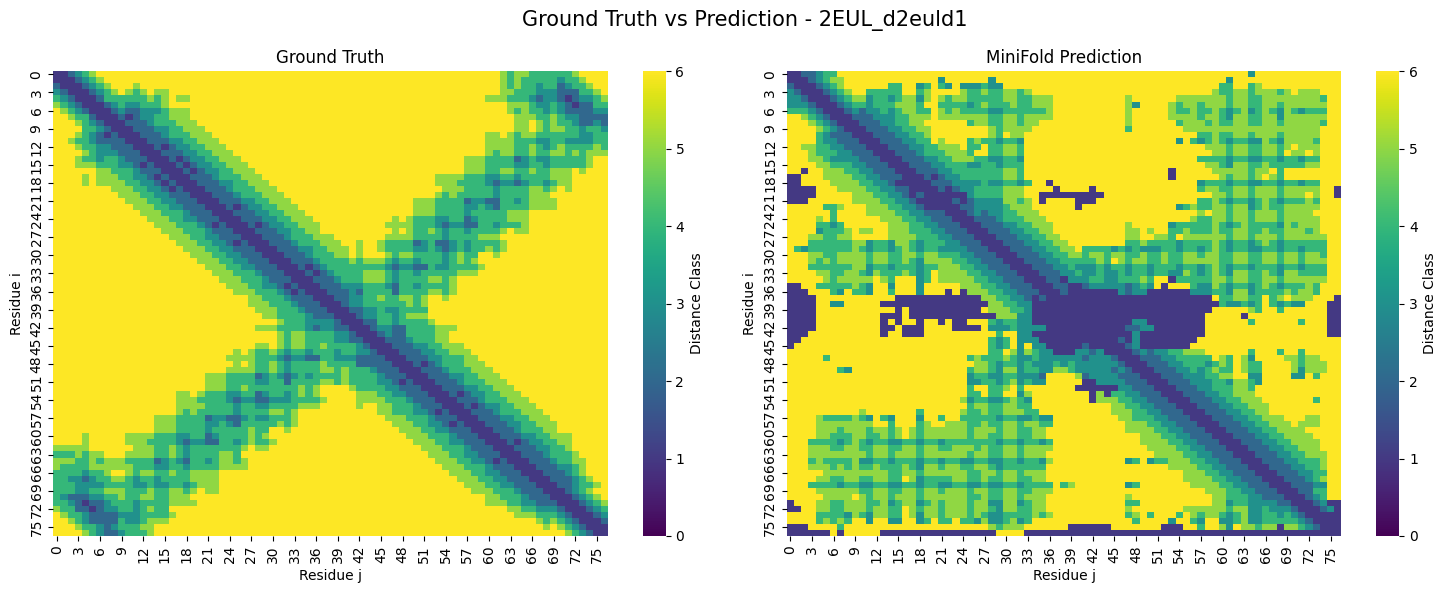

In [44]:
X, Y = generate_sample(records[0])

prediction = model(
    X[np.newaxis, ...],
    training=False
).numpy()[0]

L = len(records[0]["sequence"])

gt_map = np.argmax(Y[:L, :L], axis=-1)
pred_map = np.argmax(prediction[:L, :L], axis=-1)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(
    gt_map,
    ax=axes[0],
    cmap="viridis",
    vmin=0,
    vmax=6,
    cbar_kws={"label": "Distance Class"}
)

axes[0].set_title("Ground Truth")

sns.heatmap(
    pred_map,
    ax=axes[1],
    cmap="viridis",
    vmin=0,
    vmax=6,
    cbar_kws={"label": "Distance Class"}
)

axes[1].set_title("MiniFold Prediction")

for ax in axes:
    ax.set_xlabel("Residue j")
    ax.set_ylabel("Residue i")

fig.suptitle(
    f"Ground Truth vs Prediction - {records[0]['id']}",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "01_ground_truth_vs_prediction.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

圖二：Symmetry Analysis
蛋白質距離矩陣理論上應滿足：

D(i,j)=D(j,i)

以下比較 Ground Truth 與 Prediction 的對稱性。

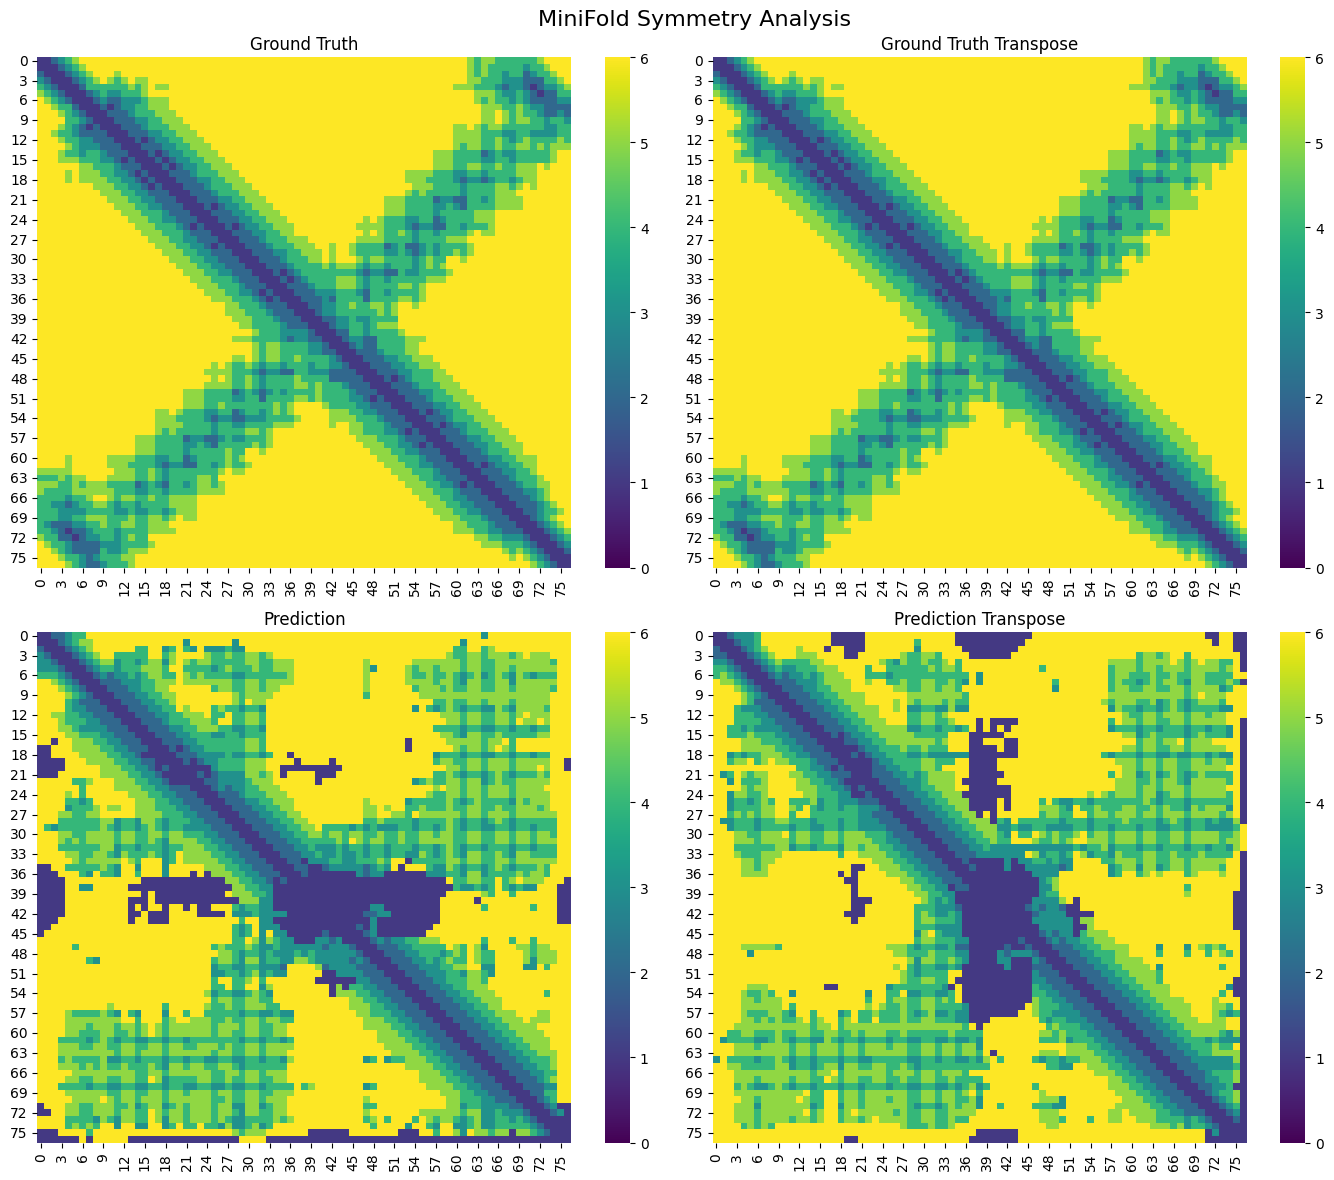

Ground Truth Symmetry: 1.0
Prediction Symmetry: 0.6000027495558776


In [45]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

sns.heatmap(
    gt_map,
    ax=axes[0, 0],
    cmap="viridis",
    vmin=0,
    vmax=6
)
axes[0, 0].set_title("Ground Truth")

sns.heatmap(
    gt_map.T,
    ax=axes[0, 1],
    cmap="viridis",
    vmin=0,
    vmax=6
)
axes[0, 1].set_title("Ground Truth Transpose")

sns.heatmap(
    pred_map,
    ax=axes[1, 0],
    cmap="viridis",
    vmin=0,
    vmax=6
)
axes[1, 0].set_title("Prediction")

sns.heatmap(
    pred_map.T,
    ax=axes[1, 1],
    cmap="viridis",
    vmin=0,
    vmax=6
)
axes[1, 1].set_title("Prediction Transpose")

plt.suptitle("MiniFold Symmetry Analysis", fontsize=16)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "02_symmetry.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Overall symmetry statistics
print("Ground Truth Symmetry:",
      protein_df["gt_symmetry"].mean())

print("Prediction Symmetry:",
      protein_df["prediction_symmetry"].mean())

圖三：Class Distribution
比較 6 個有效距離分類（排除 Padding）。

       Class  Ground Truth  Prediction
0      0-500        316718      717560
1    500-750        371234      343465
2   750-1000        459500     1373511
3  1000-1400       1187842     1685039
4  1400-1700       1052378     1670662
5      >1700       5055078     2651938


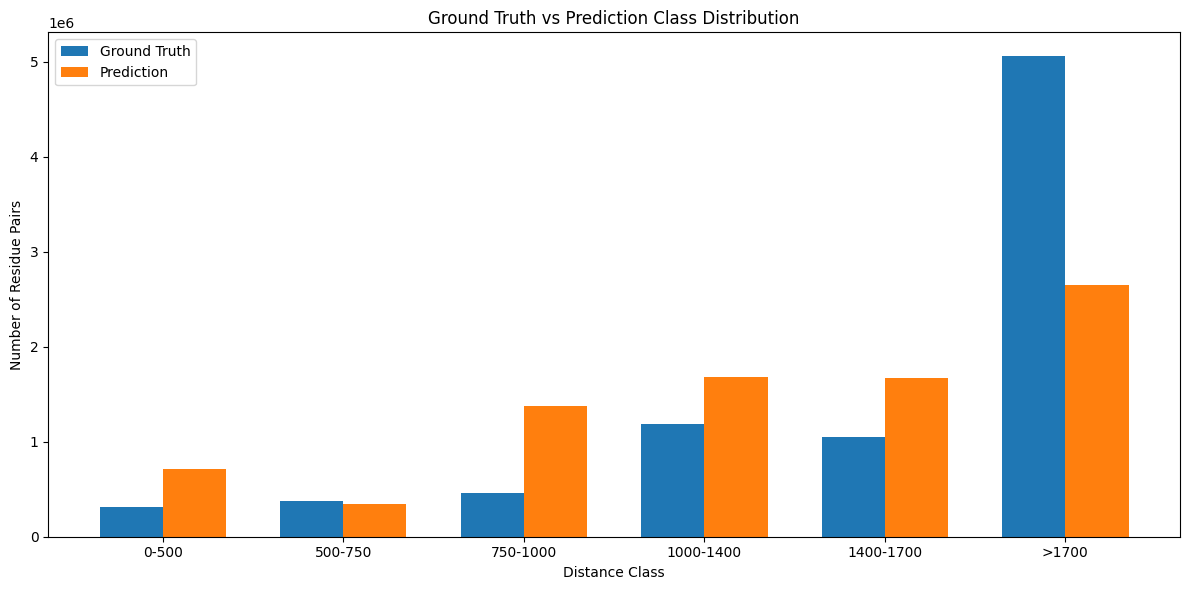

In [46]:
classes = np.arange(1, 7)

gt_counts = np.array([
    np.sum(all_gt == c)
    for c in classes
])

pred_counts = np.array([
    np.sum(all_pred == c)
    for c in classes
])

distribution_df = pd.DataFrame({

    "Class": class_names[1:],

    "Ground Truth": gt_counts,

    "Prediction": pred_counts

})

print(distribution_df)

distribution_df.to_csv(
    os.path.join(OUTPUT_DIR, "class_distribution.csv"),
    index=False
)


x = np.arange(len(classes))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    x - width/2,
    gt_counts,
    width,
    label="Ground Truth"
)

ax.bar(
    x + width/2,
    pred_counts,
    width,
    label="Prediction"
)

ax.set_xticks(x)
ax.set_xticklabels(class_names[1:])

ax.set_ylabel("Number of Residue Pairs")
ax.set_xlabel("Distance Class")

ax.set_title("Ground Truth vs Prediction Class Distribution")

ax.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "03_class_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

圖四：Prediction Accuracy
這張圖會包含 Confusion Matrix、Precision、Recall、F1-score。

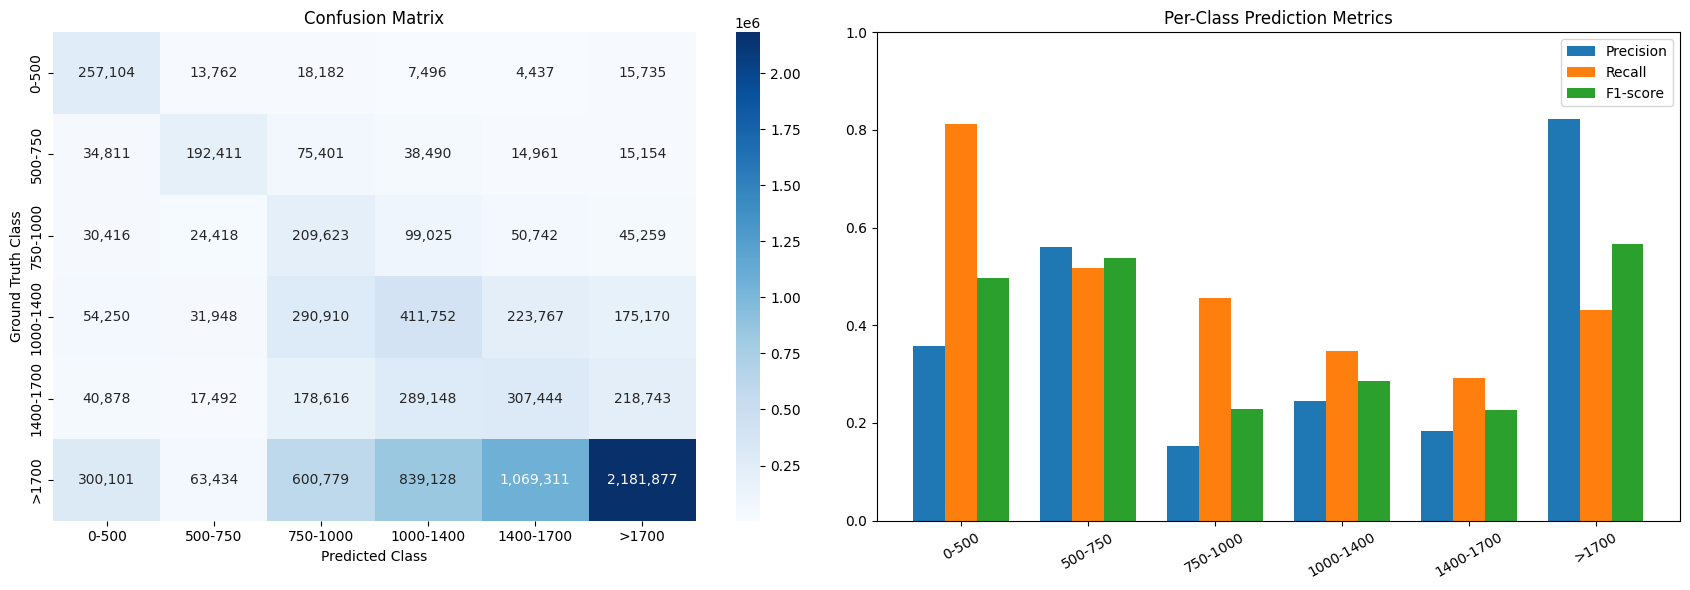

MINIFOLD EVALUATION RESULTS
Overall Accuracy : 0.4217
Macro Precision  : 0.3870
Macro Recall     : 0.4761
Macro F1-score   : 0.3905

Classification Report:
              precision    recall  f1-score   support

       0-500       0.36      0.81      0.50    316718
     500-750       0.56      0.52      0.54    371234
    750-1000       0.15      0.46      0.23    459500
   1000-1400       0.24      0.35      0.29   1187842
   1400-1700       0.18      0.29      0.23   1052378
       >1700       0.82      0.43      0.57   5055078

   micro avg       0.42      0.42      0.42   8442750
   macro avg       0.39      0.48      0.39   8442750
weighted avg       0.60      0.42      0.46   8442750



In [47]:
labels = np.arange(1, 7)

cm = confusion_matrix(
    all_gt,
    all_pred,
    labels=labels
)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Confusion Matrix
sns.heatmap(
    cm,
    annot=True,
    fmt=",",
    cmap="Blues",
    xticklabels=class_names[1:],
    yticklabels=class_names[1:],
    ax=axes[0]
)

axes[0].set_title("Confusion Matrix")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("Ground Truth Class")

# Per-class metrics
precision, recall, f1, support = (
    precision_recall_fscore_support(
        all_gt,
        all_pred,
        labels=labels,
        zero_division=0
    )
)

metric_df = pd.DataFrame({

    "Class": class_names[1:],

    "Precision": precision,

    "Recall": recall,

    "F1-score": f1,

    "Support": support

})

metric_df.to_csv(
    os.path.join(OUTPUT_DIR, "prediction_metrics.csv"),
    index=False
)

x = np.arange(6)
width = 0.25

axes[1].bar(
    x - width,
    precision,
    width,
    label="Precision"
)

axes[1].bar(
    x,
    recall,
    width,
    label="Recall"
)

axes[1].bar(
    x + width,
    f1,
    width,
    label="F1-score"
)

axes[1].set_xticks(x)
axes[1].set_xticklabels(class_names[1:], rotation=30)

axes[1].set_ylim(0, 1)

axes[1].set_title("Per-Class Prediction Metrics")
axes[1].legend()

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "04_prediction_accuracy.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


overall_accuracy = accuracy_score(all_gt, all_pred)

macro_precision = np.mean(precision)
macro_recall = np.mean(recall)
macro_f1 = np.mean(f1)

print("=" * 50)
print("MINIFOLD EVALUATION RESULTS")
print("=" * 50)

print(f"Overall Accuracy : {overall_accuracy:.4f}")
print(f"Macro Precision  : {macro_precision:.4f}")
print(f"Macro Recall     : {macro_recall:.4f}")
print(f"Macro F1-score   : {macro_f1:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        all_gt,
        all_pred,
        labels=labels,
        target_names=class_names[1:],
        zero_division=0
    )
)

7. 加入昨天的 Training History
這張圖可以觀察 35 epochs 的訓練變化。

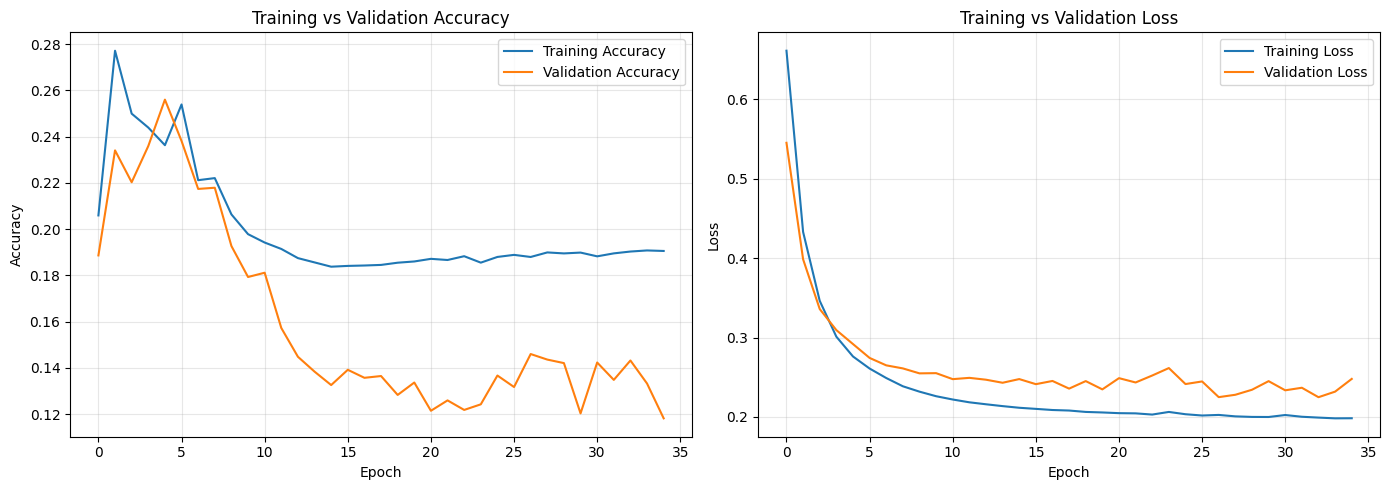

In [48]:
log = pd.read_csv(LOG_PATH)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    log["epoch"],
    log["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    log["epoch"],
    log["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].set_title("Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    log["epoch"],
    log["loss"],
    label="Training Loss"
)

axes[1].plot(
    log["epoch"],
    log["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "05_training_history.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

8. 匯出所有 Evaluation Results

In [49]:
import json
import zipfile

# Protein-level results
protein_df.to_csv(
    os.path.join(OUTPUT_DIR, "protein_evaluation.csv"),
    index=False
)

# Summary
summary = {

    "model": "MiniFold ResNet V2",

    "depth": 28,

    "input_shape": [200, 200, 42],

    "output_classes": 7,

    "total_proteins": len(records),

    "total_residue_pairs": int(len(all_gt)),

    "overall_accuracy": float(overall_accuracy),

    "macro_precision": float(macro_precision),

    "macro_recall": float(macro_recall),

    "macro_f1": float(macro_f1),

    "ground_truth_symmetry": float(
        protein_df["gt_symmetry"].mean()
    ),

    "prediction_symmetry": float(
        protein_df["prediction_symmetry"].mean()
    )

}

with open(
    os.path.join(OUTPUT_DIR, "evaluation_summary.json"),
    "w"
) as f:

    json.dump(summary, f, indent=4)


# ZIP everything
zip_path = "/kaggle/working/MiniFold_Evaluation.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for root, dirs, files in os.walk(OUTPUT_DIR):

        for file in files:

            filepath = os.path.join(root, file)

            z.write(
                filepath,
                arcname=os.path.relpath(
                    filepath,
                    OUTPUT_DIR
                )
            )


print("=" * 60)
print("MINIFOLD EVALUATION COMPLETED")
print("=" * 60)

print("Output directory:", OUTPUT_DIR)
print("ZIP file:", zip_path)

print("\nGenerated files:")

for file in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", file)

MINIFOLD EVALUATION COMPLETED
Output directory: /kaggle/working/MiniFold_Evaluation
ZIP file: /kaggle/working/MiniFold_Evaluation.zip

Generated files:
 - 01_ground_truth_vs_prediction.png
 - 02_symmetry.png
 - 03_class_distribution.png
 - 04_prediction_accuracy.png
 - 05_training_history.png
 - class_distribution.csv
 - evaluation_summary.json
 - prediction_metrics.csv
 - protein_evaluation.csv
